# Public-data extension — UCI daily bicycle rentals

## Goal
Transfer prediction-time discipline to real historical records. Fanaee-T, H. (2013), *Bike Sharing*, UCI Machine Learning Repository, DOI https://doi.org/10.24432/C5W894. CC BY 4.0. 731 daily rows, 2011–2012. The bundled data is a JSON transcription of day.csv; attribution and checksums are in DATA.md. It is historical observed rentals, not current demand or necessarily unconstrained demand.

## Setup
Decision: predict tomorrow’s rental count at the end of today. Features: completed lags plus tomorrow’s known calendar. Exclude tomorrow’s realized temperature, humidity, weather, and casual/registered user counts. Those counts sum to the target, and realized weather is not a weather forecast. We do not assume all administrative fields were available in real time; validate that before real deployment.

In [1]:
from pathlib import Path
import json
import numpy as np
import matplotlib.pyplot as plt
from workshop import *
plt.rcParams.update({'figure.figsize': (8.5, 4.2), 'font.size': 11,
                     'axes.spines.top': False, 'axes.spines.right': False,
                     'axes.grid': True, 'grid.alpha': .18})
COLORS = {'actual': '#263a36', 'model': '#4c713d', 'baseline': '#82739b'}
SEED = 42
records=json.loads(Path('data/bike-day.json').read_text())
assert len(records)==731
print('Period:',records[0]['dteday'],'to',records[-1]['dteday'])
print('Unique dates:',len({r['dteday'] for r in records}))
print('Blank field count:',sum(v=='' for r in records for v in r.values()))
print('Target identity holds:',all(int(r['casual'])+int(r['registered'])==int(r['cnt']) for r in records))

Period: 2011-01-01 to 2012-12-31
Unique dates: 731
Blank field count: 0
Target identity holds: True


## Steps
### 1. Construct lagged features and a chronological protocol
The first seven days are omitted to obtain a weekly lag. The final 90 days stay hidden during model selection. The preceding 90 days are validation. Rental counts can be affected by availability and system changes; no station stockout or causal promotion effect is identified here.

In [2]:
demand=np.array([int(r['cnt']) for r in records],float)
features=[]
for i in range(7,len(records)):
    r=records[i]
    features.append([demand[i-1],demand[i-7],int(r['workingday']),np.sin(2*np.pi*int(r['mnth'])/12),np.cos(2*np.pi*int(r['mnth'])/12),int(r['holiday'])])
x=np.array(features,float);y=demand[7:]
train_end=len(y)-180;val_end=len(y)-90
x_train,y_train=x[:train_end],y[:train_end]
x_val,y_val=x[train_end:val_end],y[train_end:val_end]
print('Rows train/validation/test:',len(y_train),len(y_val),len(y)-val_end)
model=pipeline_for(False,.1,len(y_train));model.fit(x_train,y_train)
print('Validation model:',metrics(y_val,model.predict(x_val)))
print('Validation weekly baseline:',metrics(y_val,x_val[:,1]))

Rows train/validation/test: 544 90 90
Validation model: {'mae': 883.5785761079732, 'rmse': 1053.8765758244147, 'bias': -562.1090911621473}
Validation weekly baseline: {'mae': 828.6444444444444, 'rmse': 1156.983059512973, 'bias': -61.68888888888889}


### 2. Freeze and evaluate
This notebook predeclares one ridge pipeline and its regularization. It does not search the final period. Evaluation uses the previous observed daily totals when available, appropriate for a rolling daily one-day-ahead forecast; it is not a single forecast of the whole next 90 days.

Final model: {'mae': 1140.092933777143, 'rmse': 1363.93770049495, 'bias': -441.1233316321176}
Final seasonal baseline: {'mae': 1450.4555555555555, 'rmse': 2045.931477618718, 'bias': 409.7}


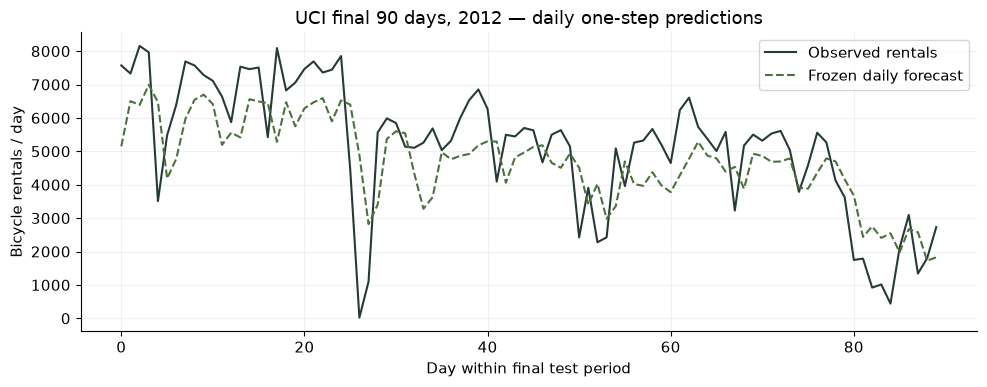

In [3]:
frozen=deepcopy(model)
x_test,y_test=x[val_end:],y[val_end:]
pred=frozen.predict(x_test)
print('Final model:',metrics(y_test,pred))
print('Final seasonal baseline:',metrics(y_test,x_test[:,1]))
fig,ax=plt.subplots(figsize=(10,4))
ax.plot(y_test,label='Observed rentals',color=COLORS['actual'])
ax.plot(pred,'--',label='Frozen daily forecast',color=COLORS['model'])
ax.set(title='UCI final 90 days, 2012 — daily one-step predictions',xlabel='Day within final test period',ylabel='Bicycle rentals / day');ax.legend();plt.tight_layout();plt.show()

## Checks
Feature eligibility is more important than apparent accuracy. Training and validation are chronological, seven-day lags use only completed days, and target-component columns are excluded. The source reports no missing fields; the executed blank-count check above checks the bundled transcription, not every possible measurement bias. This evidence is limited to a single historical system; it does not establish transfer to another city or current operation.

## Next Steps
Define a deployment population, reporting delays, operational costs, and an external temporal/site evaluation before proposing a pilot. Add forecast-weather inputs only if their historical issue timestamps are available. Keep this real-data study separate from synthetic browser scores.